# Predicción de mapas de calor (LST) en Tlaxcala y Puebla con cómputo paralelo

**Objetivo:** predecir la temperatura superficial (LST, °C) de cada pixel de 1 km en el mes *t* a partir de los mapas de calor de los meses anteriores (*t−1, t−2, t−3, t−12*), el NDVI del mes anterior, la altitud, la ubicación y el mes.

**Datos:** MODIS Terra (MOD11A2 y MOD13A3), 2015–2024, 120 mapas mensuales; descargados con `01_descarga_MODIS_GEE.js`.

**Paralelismo (multiprocessing, sin joblib ni n_jobs):**
1. Construcción de la tabla: la imagen se parte en bloques de filas, uno por proceso (paralelismo de datos).
2. Búsqueda de hiperparámetros de KNN, RF y SVR: cada combinación es una tarea (reparto estático vs. dinámico).

In [6]:
import os
for v in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ[v] = "1"

import multiprocessing as mp
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import datos

RUTA_LST = os.environ.get("RUTA_LST", "LST_mensual.tif")
RUTA_NDVI = os.environ.get("RUTA_NDVI", "NDVI_mensual.tif")
RUTA_ALT = os.environ.get("RUTA_ALT", "ALTITUD.tif")
ANIO_PRUEBA = 2024
N_MAX_ENTRENAMIENTO = int(os.environ.get("N_MAX", 40000))
NUCLEOS = mp.cpu_count()
LISTA_PROCESOS = [p for p in [1, 2, 4, 8, 16] if p <= NUCLEOS]

os.makedirs("resultados", exist_ok=True)
os.makedirs("figuras", exist_ok=True)
COLORES = {"KNN": "#2a78d6", "RF": "#eb6834", "SVR": "#1baf7a"}
plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})
print("Núcleos:", NUCLEOS, "| Procesos a medir:", LISTA_PROCESOS)

Núcleos: 8 | Procesos a medir: [1, 2, 4, 8]


## 1. Lectura de los mapas mensuales

Mapas: 120 meses de 329 x 261 pixeles


C:\Users\CHECA\AppData\Local\Temp\ipykernel_18448\1441920089.py:6: RuntimeWarning: Mean of empty slice
  im = axes[0].imshow(np.nanmean(lst[-12:], axis=0), cmap="inferno",


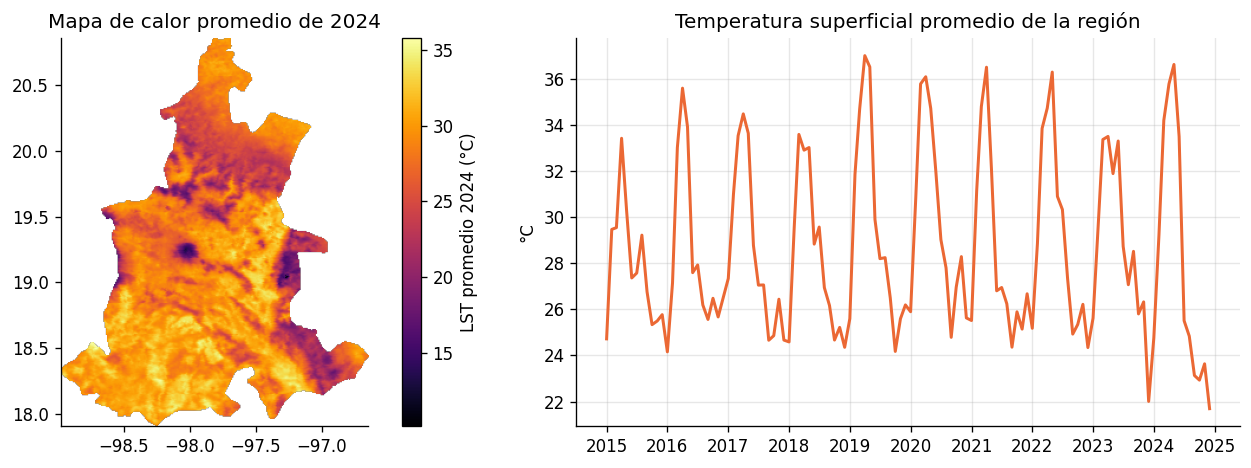

In [7]:
mapas = datos.leer_mapas(RUTA_LST, RUTA_NDVI, RUTA_ALT)
lst, ndvi, alt, lat, lon = mapas

# Mapa de calor de ejemplo y temperatura promedio de la región por mes
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
im = axes[0].imshow(np.nanmean(lst[-12:], axis=0), cmap="inferno",
                    extent=[lon[0], lon[-1], lat[-1], lat[0]])
fig.colorbar(im, ax=axes[0], label="LST promedio 2024 (°C)")
axes[0].set_title("Mapa de calor promedio de 2024"); axes[0].grid(False)
serie = np.nanmean(lst.reshape(lst.shape[0], -1), axis=1)
meses = pd.date_range(f"{datos.ANIO_INICIO}-01-01", periods=len(serie), freq="MS")
axes[1].plot(meses, serie, color="#eb6834", lw=1.8)
axes[1].set_title("Temperatura superficial promedio de la región"); axes[1].set_ylabel("°C")
fig.tight_layout(); fig.savefig("figuras/mapas_y_serie.png", dpi=200); plt.show()

## 2. Construcción de la tabla en paralelo (paralelismo de datos)

Cada fila de la tabla es un pixel en un mes. Las filas de la imagen se reparten en bloques con `nivelar()` y cada proceso arma las variables de su bloque. Se mide el tiempo con 1, 2, 4… procesos.

In [8]:
tiempos_tabla = {}
for p in LISTA_PROCESOS:
    df, t = datos.construir_variables(mapas, procesos=p)
    tiempos_tabla[p] = t
    print(f"{p:>2} procesos: {t:7.2f} s  ->  {len(df):,} filas")

t1 = tiempos_tabla[1]
tabla_tiempos = pd.DataFrame([{"procesos": p, "tiempo_s": t, "speedup": t1 / t, "eficiencia": t1 / t / p}
                              for p, t in tiempos_tabla.items()])
tabla_tiempos.to_csv("resultados/desempeno_construccion_tabla.csv", index=False)
tabla_tiempos.round(3)

 1 procesos:   15.01 s  ->  4,429,724 filas
 2 procesos:   11.34 s  ->  4,429,724 filas
 4 procesos:   11.52 s  ->  4,429,724 filas
 8 procesos:   17.77 s  ->  4,429,724 filas


,procesos,tiempo_s,speedup,eficiencia
0,1,15.008,1.000,1.000
1,2,11.337,1.324,0.662
2,4,11.518,1.303,0.326
3,8,17.770,0.845,0.106


In [9]:
# Descripción de los datos
resumen_datos = pd.DataFrame({"dato": ["Filas (pixel-mes)", "Pixeles con datos", "Meses", "Años"],
    "valor": [len(df), df.groupby(["fila", "col"]).ngroups, df[["anio", "mes"]].drop_duplicates().shape[0],
              f"{df['anio'].min()}–{df['anio'].max()}"]})
desc = df[["LST"] + datos.COLUMNAS_X[:6]].describe().T[["mean", "std", "min", "max"]].round(3)
resumen_datos.to_csv("resultados/resumen_datos.csv", index=False)
desc.to_csv("resultados/descripcion_variables.csv")
display(resumen_datos)
desc

,dato,valor
0,Filas (pixel-mes),4429724
1,Pixeles con datos,41050
2,Meses,108
3,Años,2016–2024


,mean,std,min,max
LST,28.777,6.078,0.143,51.177
LST_t1,28.813,6.050,0.143,51.177
LST_t2,28.830,6.044,0.143,51.177
LST_t3,28.851,6.029,0.143,51.177
LST_t12,28.768,5.907,0.143,51.177
NDVI_t1,0.525,0.207,-0.200,0.965
ALTITUD,1821.903,769.810,41.000,5322.000


## 3. Partición

- **Prueba:** los 12 mapas de 2024 (el modelo predice un año que nunca vio).
- **Entrenamiento y validación:** años anteriores, al azar (80% / 20%).

In [12]:
ent, val, prueba = datos.particionar(df, anio_prueba=ANIO_PRUEBA, n_max_entrenamiento=N_MAX_ENTRENAMIENTO)
X_ent, y_ent = ent[datos.COLUMNAS_X].to_numpy(), ent[datos.COLUMNA_Y].to_numpy()
X_val, y_val = val[datos.COLUMNAS_X].to_numpy(), val[datos.COLUMNA_Y].to_numpy()
X_pru, y_pru = prueba[datos.COLUMNAS_X].to_numpy(), prueba[datos.COLUMNA_Y].to_numpy()
datos_modelo = (X_ent, y_ent, X_val, y_val)

Entrenamiento: 40,000 | Validación: 50,000 | Prueba (2024): 491,336


## 4. Búsqueda de hiperparámetros en paralelo

46 combinaciones (KNN 16, RF 18, SVR 12). Reparto **dinámico**: cada proceso toma la siguiente combinación al terminar.

In [13]:
import modelos
import paralelo as par

tareas = modelos.lista_de_tareas()
print("Tareas:", len(tareas))
tiempos, resultados_por_p = {}, {}
for p in LISTA_PROCESOS:
    res, t = par.busqueda(tareas, datos_modelo, procesos=p, reparto="dinamico")
    tiempos[p] = t
    resultados_por_p[p] = pd.DataFrame(res)
    print(f"{p:>2} procesos: {t:8.2f} s")
busqueda = resultados_por_p[1].sort_values("RMSE")
busqueda.to_csv("resultados/busqueda_hiperparametros.csv", index=False)

# El resultado en paralelo debe ser igual al secuencial
base = resultados_por_p[1].set_index(["modelo", "params"])["RMSE"]
for p, r in resultados_por_p.items():
    print(f"{p:>2} procesos: diferencia máxima de RMSE = {(r.set_index(['modelo', 'params'])['RMSE'] - base).abs().max():.1e}")

Tareas: 46
 1 procesos:   978.71 s
 2 procesos:   582.63 s
 4 procesos:   292.95 s
 8 procesos:   225.63 s
 1 procesos: diferencia máxima de RMSE = 0.0e+00
 2 procesos: diferencia máxima de RMSE = 0.0e+00
 4 procesos: diferencia máxima de RMSE = 0.0e+00
 8 procesos: diferencia máxima de RMSE = 0.0e+00


,procesos,tiempo_s,speedup,eficiencia,karp_flatt
0,1,978.708,1.000,1.000,NaN
1,2,582.625,1.680,0.840,0.191
2,4,292.950,3.341,0.835,0.066
3,8,225.631,4.338,0.542,0.121


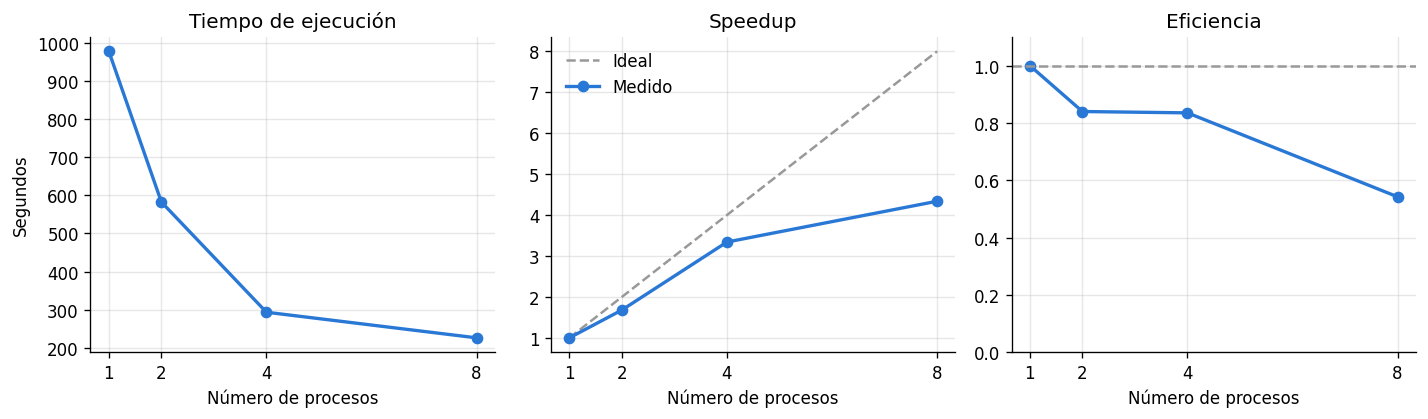

In [14]:
desempeno = par.metricas_paralelas(tiempos)
desempeno.to_csv("resultados/desempeno_paralelo.csv", index=False)
display(desempeno.round(3))

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
P = desempeno["procesos"]
axes[0].plot(P, desempeno["tiempo_s"], marker="o", color="#2a78d6", lw=2); axes[0].set_title("Tiempo de ejecución"); axes[0].set_ylabel("Segundos")
axes[1].plot(P, P, ls="--", color="#999999", lw=1.5, label="Ideal")
axes[1].plot(P, desempeno["speedup"], marker="o", color="#2a78d6", lw=2, label="Medido"); axes[1].set_title("Speedup"); axes[1].legend(frameon=False)
axes[2].plot(P, desempeno["eficiencia"], marker="o", color="#2a78d6", lw=2); axes[2].axhline(1, ls="--", color="#999999")
axes[2].set_ylim(0, 1.1); axes[2].set_title("Eficiencia")
for ax in axes:
    ax.set_xlabel("Número de procesos"); ax.set_xticks(P)
fig.tight_layout(); fig.savefig("figuras/desempeno_paralelo.png", dpi=200); plt.show()

## 5. Nivelación de cargas: reparto estático vs. dinámico

In [15]:
p_max = max(LISTA_PROCESOS)
if p_max > 1:
    _, t_est = par.busqueda(tareas, datos_modelo, procesos=p_max, reparto="estatico")
    comparacion = pd.DataFrame({"reparto": ["Estático (nivelar)", "Dinámico (imap_unordered)"],
                                "procesos": [p_max, p_max], "tiempo_s": [t_est, tiempos[p_max]],
                                "speedup": [tiempos[1] / t_est, tiempos[1] / tiempos[p_max]]})
    comparacion.to_csv("resultados/estatico_vs_dinamico.csv", index=False)
    display(comparacion.round(3))
carga = resultados_por_p[1].groupby("modelo")["segundos"].agg(["count", "sum", "mean"]).round(2)
carga.columns = ["tareas", "segundos_totales", "segundos_por_tarea"]
carga

,reparto,procesos,tiempo_s,speedup
0,Estático (nivelar),8,327.844,2.985
1,Dinámico (imap_unordered),8,225.631,4.338


,tareas,segundos_totales,segundos_por_tarea
modelo,,,
KNN,16,79.90,4.99
RF,18,445.02,24.72
SVR,12,453.53,37.79
